In [1]:
import agama, numpy
from astropy import units as u 
from astropy import constants as cnst
import h5py 
from matplotlib import pyplot as plt 
from matplotlib.gridspec import GridSpec

plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})

In [2]:
def print_tree(group, indent=0):
    pad = "    " * indent
    for key, item in group.items():
        if isinstance(item, h5py.Group):          # public name; avoid h5py._hl.group.Group
            print(f"{pad}{key}/   ({len(item.attrs)} attrs)")
            print_tree(item, indent + 1)
        else:
            print(f"{pad}{key}   {item.shape} {item.dtype}")

In [3]:
# open the output file and analyze it 
myfile=h5py.File("ferrers_bar_10000.h5",'r')
print_tree(myfile)

nbody_10000/   (28 attrs)
    initial_conditions   (10000, 6) float64
    mass   (10000,) float64
    potential_energy_external   (20001, 10000) float32
    potential_energy_internal   (20001, 10000) float32
    time   (20001,) float64
    trajectories   (20001, 10000, 6) float32
schwarzschild/   (30 attrs)
    gridr   (11,) float64
    ics   (2000, 6) float64
    inputs/   (0 attrs)
        bar_ini   () object
        ext_ini   () object
    mass_model   (191,) float64
    mass_true   (191,) float64
    matrix_data_density   (2000, 191) float32
    orbit_times   (2000,) float64
    potential/   (1 attrs)
        bar/   (5 attrs)
        halo/   (3 attrs)
        thick_disk/   (4 attrs)
        thin_disk/   (4 attrs)
    sigma   (191,) float64
    trajectories/   (0 attrs)
        data   (3254220, 6) float64
        offsets   (2001,) int64
        time   (3254220,) float64
    weights   (2000,) float64


### Analysis and checks 

- Total energy conservation 
- animation
- Jacobi energy of each star ?
- movement in E,L_z plane

In [4]:
# I should down sample the time 
group = "nbody_10000"
mass = myfile[group]["mass"][:]
trajectories=myfile[group]["trajectories"]
nbody=mass.shape[0]
potential_energy_external = mass*myfile[group]["potential_energy_external"][:]
potential_energy_internal = 0.5*mass*myfile[group]["potential_energy_internal"][:]
kinetic_energy = (1/2)*mass*numpy.sum(trajectories[:,:,3:6]**2,axis=2)
timesteps = myfile[group]["time"][:]
Lz = trajectories[:,:,0]*trajectories[:,:,4] - trajectories[:,:,1]*trajectories[:,:,3]


In [5]:
timesteps = myfile[group]["time"][:]*myfile[group].attrs['unitT'] * u.s*u.kpc/u.km
timesteps=timesteps.to(u.Gyr).value

In [6]:
omega = myfile["schwarzschild"].attrs['omega']
E_total = potential_energy_external + potential_energy_internal + kinetic_energy
total_energy = numpy.sum(E_total,axis=1)
jacobii = E_total - omega * Lz
total_jacobii=numpy.sum(jacobii,axis=1)

In [7]:
Lz_total = numpy.sum(Lz,axis=1)
dLz = numpy.abs((Lz_total-Lz_total[0])/Lz_total)
eDrift = numpy.abs((total_energy - total_energy[0]) / total_energy[0])
dJacobii = numpy.abs((total_jacobii - total_jacobii[0])/total_jacobii[0])

In [8]:
bbox=dict(boxstyle="square",color="white",alpha=0.9)

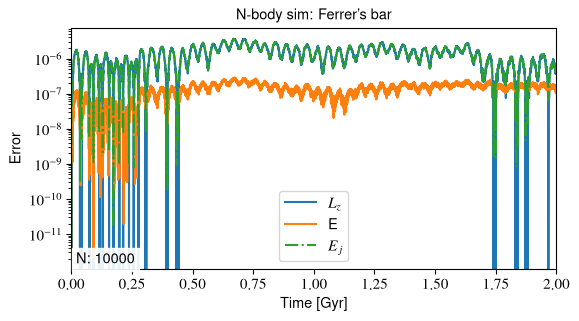

In [15]:
fig,axis=plt.subplots(1,1,figsize=((8.26-2),(8.26-2)/2),sharex=True)
axis.plot(timesteps,dLz,label=r"$L_z$")
axis.plot(timesteps,eDrift,label="E")
axis.plot(timesteps,dJacobii,label=r"$E_j$",linestyle="-.")
axis.set(ylabel="Error",yscale="log",xlabel='Time [Gyr]',xlim=[timesteps.min(),timesteps.max()],title="N-body sim: Ferrer's bar")
axis.legend()
axis.text(0.01,0.01,s="N: {:d}".format(nbody),transform=axis.transAxes,bbox=bbox,ha="left",va="bottom");
# axis[1].set(ylabel=r"$dL_z$",xlabel="time",yscale="log")
# fig.savefig(f"test_total_energy_conservation_{group}.png",dpi=300)

In [55]:
nbins = numpy.sqrt(nbody)
unitE=myfile[group].attrs['unitV']**2 / 1e3
bins=unitE*numpy.linspace(jacobii[:].min(), jacobii[:].max(),int(2*nbins))

In [105]:
import matplotlib.colors
norm=matplotlib.colors.Normalize(vmin=jacobii.min()/2,vmax=jacobii.max()/2)
cmap=plt.get_cmap("rainbow")
mycolors = cmap(norm(jacobii[0,:]))

In [198]:
path = "ferrers_bar_10000/nbody_10000/"

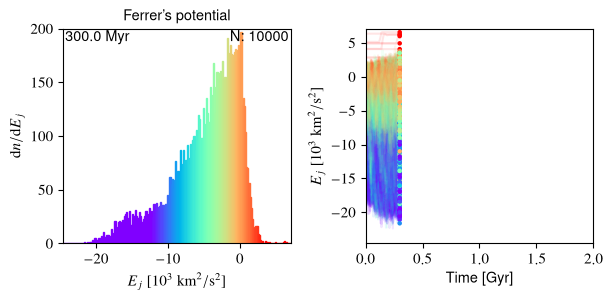

In [202]:
# let's look at the initial distributioon
NNSKIP = 100
timestep_indexes=numpy.arange(0,timesteps.shape[0],dtype=int)
frame_indexes = numpy.arange(0,timesteps.shape[0]/NNSKIP,dtype=int)

fig,axis=plt.subplots(1,2,figsize=((8.26-2),(8.26-2)/2))

# iterate over the frames
cc = 30
timeindex=timestep_indexes[NNSKIP*cc]
# set up the plot 
axis[0].set(xlabel=r"$E_j~[10^3~\mathrm{km}^2/\mathrm{s}^2]$",ylabel=r"$\mathrm{d}n/\mathrm{d}E_j$",xlim=[bins.min(),bins.max()],ylim=[0,200],title="Ferrer's potential");
axis[0].text(0.99,0.99,s="N: {:d}".format(nbody),transform=axis[0].transAxes,ha="right",va="top");

# plot the energy for star
for i in range(nbody):
    axis[1].plot(timesteps[0:timeindex:NNSKIP],unitE*jacobii[0:timeindex:NNSKIP,i],c=mycolors[i],alpha=.1)
axis[1].set(xlim=[0,timesteps.max()],ylim=[unitE*jacobii.min(),unitE*jacobii.max()],ylabel=r"$E_j~[10^3~\mathrm{km}^2/\mathrm{s}^2]$",xlabel="Time [Gyr]")
# plot the current position, but color it by the initial energy 
axis[1].scatter(timesteps[timeindex]*numpy.ones_like(jacobii[timeindex,:]),unitE*jacobii[timeindex,:],color=mycolors,s=5,zorder=1000)

# get the histogram of the distribution of jacobii energies 
counts, edges, patches = axis[0].hist(
    unitE * jacobii[timeindex, :],
    bins=bins,
    edgecolor="black",
)

centers = (edges[:-1] + edges[1:]) / 2
colors = cmap(norm(centers / unitE))
# recolor all the bins based on the jacobii energy 
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)
    patch.set_edgecolor(color)
axis[0].text(0.01,0.99,s="{:.1f} Myr".format(1000*timesteps[timeindex]),transform=axis[0].transAxes,ha="left",va="top");

fig.tight_layout()
# save the frame
fig.savefig(path+"frame_{:06d}.png".format(frame_indexes[cc]),dpi=300)